# How long a lookback window helps the forecast?

给模型输入预测目标日期前连续最近1至28天的数据，比较同一模型在不同回看窗口长度下的变化；输出最佳的look-back窗口天数；

结果总览：

NN在输入预测目标日期前连续最近两天的数据时，RMSE衡量的表现最佳

| Model | Windows scored | Best lookback (days) | Best RMSE | 1-day lookback | 7-day lookback | 28-day lookback |
|---|---:|---:|---:|---:|---:|---:|
| Baseline | 28/28 | 15 | 3.063 | 3.305 | 3.089 | 3.068 |
| LinearRegression | 28/28 | 2 | 2.615 | 2.800 | 2.665 | 3.120 |
| Ridge | 28/28 | 2 | 2.614 | 2.799 | 2.657 | 3.050 |
| Lasso | 28/28 | 5 | 2.640 | 2.817 | 2.648 | 2.835 |
| ElasticNet | 28/28 | 5 | 2.639 | 2.818 | 2.652 | 2.887 |
| Poly | 28/28 | 1 | 3.430 | 3.430 | 6.500 | 4.289 |
| Poly Lasso | 28/28 | 5 | 2.616 | 2.738 | 2.619 | 2.682 |
| Poly Ridge | 28/28 | 2 | 2.851 | 2.980 | 3.255 | 4.071 |
| KNN | 28/28 | 1 | 3.137 | 3.137 | 3.861 | 4.088 |
| SVR | 28/28 | 4 | 2.632 | 2.808 | 2.661 | 3.005 |
| RandomForest | 28/28 | 2 | 2.656 | 2.678 | 2.724 | 2.760 |
| NN | 28/28 | 2 | 2.584 | 2.702 | 2.719 | 3.240 |

In [1]:
from pathlib import Path
import sys

# Launch from the project root or this subfolder.
here = Path.cwd()
if not (here / "experiments.py").exists():
    here = here / "regression_inputs"
sys.path.insert(0, str(here.resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from experiments import Inputs, MODELS, LINEAR, SETTINGS, evaluate, summarize

# Saved scores refer to this exact weather file.
from hashlib import sha256
from experiments import DATA
if sha256(DATA.read_bytes()).hexdigest() != "e1ac9e85c904d3b35bfcc4ee3bb30d8e8e47a7f78d76454ebcc5b9586dd71ea5":
    print("Weather CSV changed. Refit every model before comparing with the saved scores.")

part = 1
study = Inputs(part)
# False displays the committed measurements. True runs every missing fold.
RUN_FULL = False
# Limit this list to one family for a smaller new run.
MODELS_TO_FIT = MODELS.copy()
RUN_SELECTED_TEST = False
print("All model entries:", ", ".join(MODELS))
print(f"{len(study.dates):,} targets, {study.dates[0].date()} through {study.dates[-1].date()}")
print("First test date:", study.test_start.date())

All model entries: Baseline, LinearRegression, Ridge, KNN, Lasso, ElasticNet, SVR, NN, RandomForest, Poly, Poly Ridge, Poly Lasso
6,913 targets, 2006-01-29 through 2025-01-01
First test date: 2021-03-17


### Check one forecast row

For January 1, 2025, a model with a seven-day lookback window sees December 25–31. A model with a 28-day lookback window also sees December 4–24. The answer is always the mean temperature on January 1.

In [2]:
example = study.dates.get_loc("2025-01-01")
X7, binary7 = study.matrix(7)
assert X7.shape[1] == 133 and len(binary7) == 7
# Bill orders fields first, with lags 1 through 7 inside each field.
assert X7[example, 0] == study.weather.loc["2024-12-31", "temperature_2m_mean"]
assert X7[example, 6] == study.weather.loc["2024-12-25", "temperature_2m_mean"]
assert X7[example, binary7[0]] == study.weather.loc["2024-12-31", "weather_code"]
assert study.y[example] == study.weather.loc["2025-01-01", "temperature_2m_mean"]
del X7
print("Seven-day lookback row verified for January 1, 2025.")

Seven-day lookback row verified for January 1, 2025.


### Which dates train and validate each model?

In [3]:
splits = []
for fold, (train, valid) in enumerate(study.splits(), start=1):
    splits.append([fold, len(train), study.dates[train[0]].date(), study.dates[train[-1]].date(),
                   len(valid), study.dates[valid[0]].date(), study.dates[valid[-1]].date()])
display(pd.DataFrame(splits, columns=["Fold", "Train days", "Train start", "Train end",
                                      "Validation days", "Validation start", "Validation end"]))

,Fold,Train days,Train start,Train end,Validation days,Validation start,Validation end
0,1,921,2006-01-29,2008-08-06,921,2008-08-07,2011-02-13
1,2,1842,2006-01-29,2011-02-13,921,2011-02-14,2013-08-22
2,3,2763,2006-01-29,2013-08-22,921,2013-08-23,2016-02-29
3,4,3684,2006-01-29,2016-02-29,921,2016-03-01,2018-09-07
4,5,4605,2006-01-29,2018-09-07,921,2018-09-08,2021-03-16


### Model and scoring conventions

所有模型的选择和设定都和main.ipynb中齐平；

In [4]:
saved = pd.read_csv(here / "validation_folds.csv")
scores = saved.loc[saved.part.eq(part)].copy()
if part == 1:
    scores["setting"] = scores.setting.astype(int)
if RUN_FULL:
    fresh_rows = []
    for setting in study.settings:
        print(f"Evaluating {setting} ...", flush=True)
        for model in MODELS_TO_FIT:
            fresh_rows.append(evaluate(study, [model], [setting]))
            print(f"  {model} complete", flush=True)
    fresh = pd.concat(fresh_rows, ignore_index=True)
    scores = pd.concat([scores.loc[~scores.model.isin(MODELS_TO_FIT)], fresh], ignore_index=True)

summary = summarize(scores)
assert summary.folds.eq(5).all()
# Only complete five-fold comparisons enter this table.
errors = summary.pivot(index="setting", columns="model", values="cv_rmse").reindex(
    index=study.settings, columns=MODELS)
print(f"{int(errors.notna().sum().sum())} of {errors.size} setting/model pairs scored.")
print("Mean validation RMSE (°C), smaller is better. A dash indicates an unmeasured combination.")
display(errors.map(lambda value: "—" if pd.isna(value) else f"{value:.3f}"))
warnings_seen = summary.loc[summary.convergence_warning, ["model", "setting"]]
if len(warnings_seen):
    print("The solver reported a convergence warning in at least one fold for these lookback windows:")
    affected = warnings_seen.groupby("model")["setting"].apply(lambda series: ", ".join(map(str, sorted(series))))
    display(affected.rename("Affected lookback windows").to_frame())

336 of 336 setting/model pairs scored.
Mean validation RMSE (°C), smaller is better. A dash indicates an unmeasured combination.
The solver reported a convergence warning in at least one fold for these lookback windows:


model,Baseline,LinearRegression,Ridge,KNN,Lasso,ElasticNet,SVR,NN,RandomForest,Poly,Poly Ridge,Poly Lasso
setting,,,,,,,,,,,,
1,3.305,2.800,2.799,3.137,2.817,2.818,2.808,2.702,2.678,3.430,2.980,2.738
2,3.305,2.615,2.614,3.376,2.692,2.689,2.660,2.584,2.656,146.595,2.851,2.636
3,3.166,2.619,2.618,3.555,2.661,2.655,2.640,2.636,2.693,217.223,2.944,2.627
4,3.147,2.629,2.628,3.655,2.649,2.648,2.632,2.620,2.696,46.307,2.978,2.625
5,3.113,2.631,2.629,3.730,2.640,2.639,2.636,2.655,2.718,20.155,3.064,2.616
6,3.098,2.649,2.644,3.794,2.644,2.646,2.652,2.683,2.724,9.849,3.162,2.631
7,3.089,2.665,2.657,3.861,2.648,2.652,2.661,2.719,2.724,6.500,3.255,2.619
8,3.081,2.681,2.673,3.921,2.654,2.660,2.675,2.739,2.738,5.445,3.383,2.630
9,3.074,2.691,2.682,3.948,2.655,2.663,2.686,2.766,2.732,5.136,3.462,2.635


,Affected lookback windows
model,
ElasticNet,"18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28"
NN,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28"
Poly Lasso,"10, 15, 24, 25, 26, 27, 28"


### How does each model respond to more history?

将每种模型在input数据范围变化下的变动绘制进行对比， Gaps indicate unmeasured windows. 7天回看窗口的位置用虚线标出；

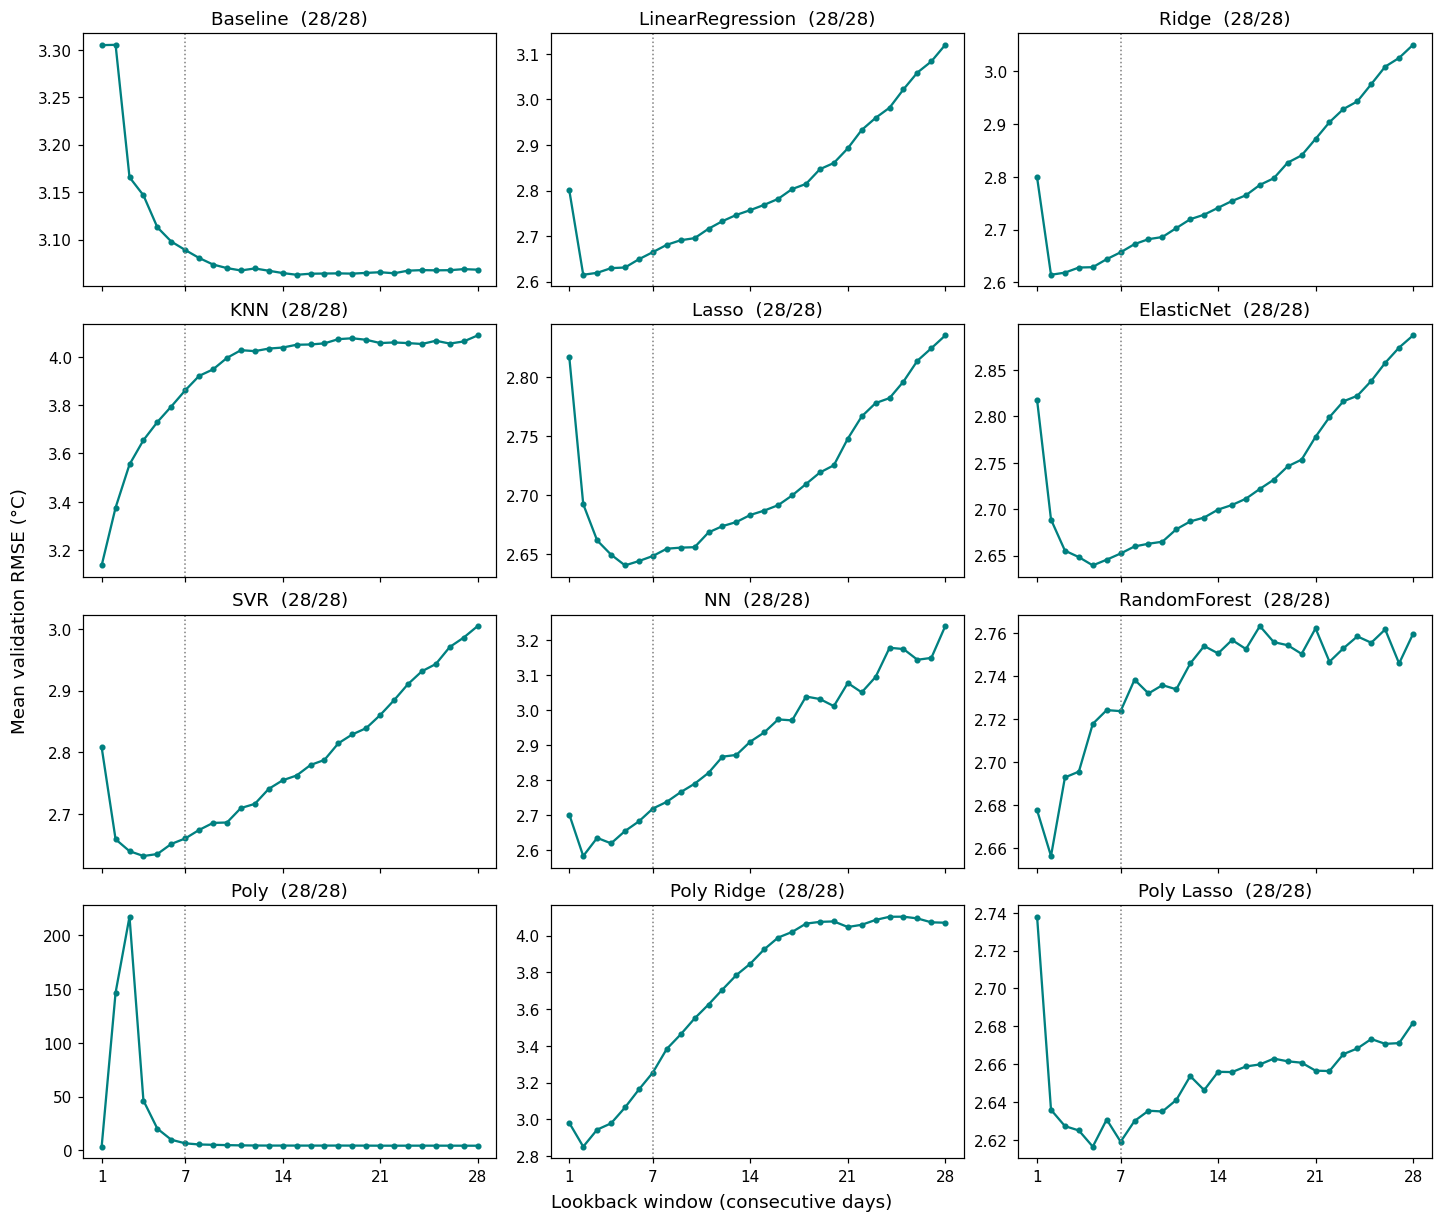

,windows_scored,best_lookback_days,best_RMSE,1_day,7_days,28_days,28_minus_7
model,,,,,,,
Baseline,28,15,3.063,3.305,3.089,3.068,-0.021
LinearRegression,28,2,2.615,2.800,2.665,3.120,0.455
Ridge,28,2,2.614,2.799,2.657,3.050,0.393
KNN,28,1,3.137,3.137,3.861,4.088,0.227
Lasso,28,5,2.640,2.817,2.648,2.835,0.187
ElasticNet,28,5,2.639,2.818,2.652,2.887,0.235
SVR,28,4,2.632,2.808,2.661,3.005,0.344
NN,28,2,2.584,2.702,2.719,3.240,0.521
RandomForest,28,2,2.656,2.678,2.724,2.760,0.036


In [5]:
fig, axes = plt.subplots(4, 3, figsize=(13, 11), sharex=True, constrained_layout=True)
for ax, model in zip(axes.flat, MODELS):
    series = errors[model]
    ax.plot(series.index, series, ".-", color="teal")
    ax.axvline(7, color="gray", linestyle=":", linewidth=1)
    ax.set_title(f"{model}  ({series.count()}/28)")
    ax.set_xticks([1, 7, 14, 21, 28])
fig.supxlabel("Lookback window (consecutive days)")
fig.supylabel("Mean validation RMSE (°C)")
plt.show()

counts = errors.count()
comparison = pd.DataFrame({
    "windows_scored": counts,
    "best_lookback_days": errors.idxmin().where(counts.eq(28)).astype("Int64"),
    "best_RMSE": errors.min().where(counts.eq(28)),
    "1_day": errors.loc[1], "7_days": errors.loc[7], "28_days": errors.loc[28]
})
comparison["28_minus_7"] = comparison["28_days"] - comparison["7_days"]
display(comparison.round(3))

### How each model responds to a seven-day lookback window

All 12 rows have five-fold results for both one-day and seven-day lookback windows. Negative differences mean extending the lookback window by six days helped.

In [6]:
week = errors.loc[[1, 7]].T.copy()
week.columns = ["1-day lookback", "7-day lookback"]
week["7-day minus 1-day lookback (°C)"] = week["7-day lookback"] - week["1-day lookback"]
display(week.sort_values("7-day minus 1-day lookback (°C)").round(3))

,1-day lookback,7-day lookback,7-day minus 1-day lookback (°C)
model,,,
Baseline,3.305,3.089,-0.216
Lasso,2.817,2.648,-0.169
ElasticNet,2.818,2.652,-0.165
SVR,2.808,2.661,-0.147
Ridge,2.799,2.657,-0.142
LinearRegression,2.800,2.665,-0.135
Poly Lasso,2.738,2.619,-0.119
NN,2.702,2.719,0.017
RandomForest,2.678,2.724,0.046


### What the complete comparison shows

Ordinary linear regression and Ridge both had their lowest five-fold RMSE with a **2-day lookback window** (about **2.615°C** each). For ordinary linear regression, a 7-day lookback window scored **2.665°C** and a 28-day lookback window scored **3.120°C**. KNN’s lowest error was with a **1-day lookback window** (**3.137°C**), while SVR reached its minimum with a **4-day lookback window** (**2.632°C**). The temperature-only linear baseline behaved differently. It reached **3.063°C** with a 15-day lookback window, and its result with a 28-day lookback window was close (**3.068°C**). Treat the exact winning lookback window as an estimate on these folds.

The nonlinear models did not all respond the same way. Extending the lookback window from one to seven days helped polynomial Lasso (2.738 to 2.619°C) and SVR (2.808 to 2.661°C). KNN worsened (3.137 to 3.861°C), and the unregularized quadratic model’s error rose from 3.430 to 6.500°C.

With a 7-day lookback window, ordinary linear regression benefits from all 19 fields (2.665°C vs 3.089°C for temperature alone). With a 28-day lookback window, that comparison reverses (3.120°C vs 3.068°C). Each extra day in the lookback window adds 19 predictors to the all-weather models, which gives them more ways to fit variation in the training set. For KNN, older measurements also change which days count as neighbors. These are possible explanations for the curves.

Across all 28 lookback windows, the best validation settings for the three models highlighted in Bill’s notebook were:

- **Poly Lasso**: a 5-day lookback window, 2.616°C RMSE. A 7-day lookback window gave 2.619°C and a 28-day lookback window gave 2.682°C.
- **NN**: a 2-day lookback window, 2.584°C RMSE. A 7-day lookback window gave 2.719°C and a 28-day lookback window gave 3.240°C.
- **RandomForest**: a 2-day lookback window, 2.656°C RMSE. A 7-day lookback window gave 2.724°C and a 28-day lookback window gave 2.760°C.


### Final score on the reserved dates

In [7]:
if RUN_SELECTED_TEST:
    if errors.isna().any().any():
        raise ValueError("Complete the comparison with RUN_FULL=True before selecting by validation.")
    # Each model's input design is selected on validation only.
    selected = {model: errors[model].idxmin() for model in MODELS}
    held = pd.concat([evaluate(study, [model], [setting], test=True)
                      for model, setting in selected.items()], ignore_index=True)
    display(held.groupby(["model", "setting"]).agg(test_rmse=("rmse", "mean"),
            mae=("mae", "mean"), seeds=("seed", "nunique")).round(3))
else:
    print("Holdout scoring is off. Validation determines the preferred inputs.")

Holdout scoring is off. Validation determines the preferred inputs.
